# Nomenclatura e força dos ácidos
### Funções inorgânicas — ácidos

**Objetivo:** Nomear ácidos a partir do ânion (eto/ito/ato → ídrico/oso/ico) e estimar a força dos oxiácidos com a regra de Pauling.

### Como usar este notebook

Execute as células na ordem, de cima para baixo. As células Markdown apresentam os conceitos; as células de código fazem as contas e geram as visualizações com **RDKit**, **py3Dmol** e **Matplotlib**.

> **Moléculas em 3D:** clique na figura e **arraste o mouse** — ela gira em 360° em qualquer direção. Use a roda do mouse (ou dois dedos no celular) para dar zoom. As cores seguem a convenção dos químicos (C = cinza, H = branco, O = vermelho, N = azul, S = amarelo, Cl = verde, Na = violeta).

In [1]:
# @title Preparar o ambiente (só precisa rodar uma vez)
import importlib.util, subprocess, sys

def _tem(modulo):
    return importlib.util.find_spec(modulo) is not None

for pacote in ("rdkit", "py3Dmol"):
    if not _tem(pacote):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pacote], check=True)

import rdkit, py3Dmol
print("rdkit", rdkit.__version__, "| py3Dmol", py3Dmol.__version__)

rdkit 2026.09.2 | py3Dmol 3.0.0


## 1. Conceito principal

A nomenclatura dos ácidos segue a terminação do ânion que eles formam:

| Ânion | Sufixo do ácido | Exemplo |
|---|---|---|
| eto | **ídrico** | $\mathrm{Cl^-}$ → $\mathrm{HCl}$ = ácido clor**ídrico** |
| ito | **oso** | $\mathrm{SO_3^{2-}}$ → $\mathrm{H_2SO_3}$ = ácido sulfur**oso** |
| ato | **ico** | $\mathrm{SO_4^{2-}}$ → $\mathrm{H_2SO_4}$ = ácido sulfúr**ico** |

Regra mnemônica: **"eto vira ídrico; ito vira oso; ato vira ico."** Os que têm menos oxigênio ganham o sufixo *oso*, os mais oxigenados o *ico*.

A força do ácido (oxiácido) cresce com o número de oxigênios e com a eletronegatividade do elemento central. Uma régua prática são as regras de Pauling, em que $n$ é o número de oxigênios **não** ligados ao hidrogênio:

$$
\boxed{\mathrm{p}K_a \approx 8 - 5n}
$$

$n = 0$ → força de ácido fraco (ácido hipocloroso, $\mathrm{p}K_a \approx 7{,}5$); $n = 1$ → forte (ácido cloroso, 2,0); $n = 2$ → muito forte (clórico, $\approx-1$); $n = 3$ → perclórico.

## 2. Exemplo resolvido passo a passo

Comparar os quatro oxiácidos do cloro: $\mathrm{HClO}$, $\mathrm{HClO_2}$, $\mathrm{HClO_3}$ e $\mathrm{HClO_4}$.

**Passo 1 — contar $n$ (O terminais).**

| Ácido | Nome | O totais | O–H | $n$ | $\mathrm{p}K_a$ previsto |
|---|---|---|---|---|---|
| $\mathrm{HClO}$ | hipocloroso | 1 | 1 | 0 | 8 |
| $\mathrm{HClO_2}$ | cloroso | 2 | 1 | 1 | 3 |
| $\mathrm{HClO_3}$ | clórico | 3 | 1 | 2 | $-2$ |
| $\mathrm{HClO_4}$ | perclórico | 4 | 1 | 3 | $-7$ |

**Passo 2 — aplicar a régua.**

$$
\mathrm{p}K_a \approx 8 - 5n
\qquad\Rightarrow\qquad
8;\ 3;\ -2;\ -7
$$

**Passo 3 — conclusão.**

A ordem de força é $\mathrm{HClO} < \mathrm{HClO_2} < \mathrm{HClO_3} < \mathrm{HClO_4}$. Os valores reais ($7{,}5$; $2{,}0$; $-1{,}0$; $-10$) confirmam a tendência: cada oxigênio a mais deixa o ácido cerca de $10^5$ vezes mais forte. O motivo é a **ressonância**: os oxigênios puxam a densidade eletrônica e estabilizam o ânion $\mathrm{ClO_4^-}$.

## 3. Conferindo o cálculo com Python

In [2]:
# @title Regra de Pauling aplicada aos oxiácidos do cloro
import math

def pka_pauling(oxigenios_terminais):
    """pKa aproximado pela regra de Pauling: 8 - 5n."""
    return 8 - 5 * oxigenios_terminais

oxiacidos = [
    ("HClO",   "hipocloroso", 0, 7.5),
    ("HClO2",  "cloroso",     1, 2.0),
    ("HClO3",  "clorico",     2, -1.0),
    ("HClO4",  "perclorico",  3, -10.0),
]

print(f"{'ácido':8s} {'nome':13s} {'n':>2s} {'pKa previsto':>13s} {'pKa real':>9s}")
for formula, nome, n, real in oxiacidos:
    print(f"{formula:8s} {nome:13s} {n:2d} {pka_pauling(n):13.0f} {real:9.1f}")

print()
for formula, nome, n, _ in oxiacidos[1:]:
    print(f"{formula:6s} é cerca de 10^5 (100 mil) vezes mais forte que o anterior")

ácido    nome           n  pKa previsto  pKa real
HClO     hipocloroso    0             8       7.5
HClO2    cloroso        1             3       2.0
HClO3    clorico        2            -2      -1.0
HClO4    perclorico     3            -7     -10.0

HClO2  é cerca de 10^5 (100 mil) vezes mais forte que o anterior
HClO3  é cerca de 10^5 (100 mil) vezes mais forte que o anterior
HClO4  é cerca de 10^5 (100 mil) vezes mais forte que o anterior


## 4. Visualização

### 4.1 Ácido sulfúrico em 3D — arraste para girar

O $\mathrm{H_2SO_4}$ é diprótico: dois $-OH$ ligados ao enxofre, e dois $\mathrm{S=O}$ terminais. Gire a figura e repare que o enxofre é tetraédrico (todos os ângulos próximos de 109°).

In [3]:
# @title Molécula 3D interativa — arraste com o mouse para girar 360°
from rdkit import Chem
from rdkit.Chem import AllChem
import py3Dmol

def molecula_3d(smiles, largura=680, altura=440):
    """SMILES -> visualização 3D interativa (arrastar = girar, roda = zoom)."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    mol = Chem.AddHs(mol)                      # H explícitos: aparecem na figura

    parametros = AllChem.ETKDGv3()
    parametros.randomSeed = 0xC0FFEE           # mesmo desenho em toda execução
    if AllChem.EmbedMolecule(mol, parametros) != 0:
        raise RuntimeError(f"não foi possível gerar a geometria 3D de {smiles!r}")

    if AllChem.MMFFHasAllMoleculeParams(mol):
        AllChem.MMFFOptimizeMolecule(mol)      # relaxa a estrutura
    else:
        AllChem.UFFOptimizeMolecule(mol)       # cobre íons sem parâmetros MMFF

    visor = py3Dmol.view(width=largura, height=altura)
    visor.addModel(Chem.MolToMolBlock(mol), "mol")
    visor.setStyle({"stick": {"radius": 0.13, "colorscheme": "Jmol"},
                    "sphere": {"scale": 0.28, "colorscheme": "Jmol"}})
    visor.setBackgroundColor("#ffffff")
    visor.zoomTo()
    return visor

molecula_3d("OS(=O)(=O)O")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.2 Ácido fosfórico em 3D

O $\mathrm{H_3PO_4}$ também é tetraédrico, com **três** $-OH$ e um $\mathrm{P=O}$. É o ácido dos refrigerantes tipo cola (o que dá o "ardinho" característico).

In [4]:
molecula_3d("OP(=O)(O)O")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.3 Os dois em 2D, com os risquinhos

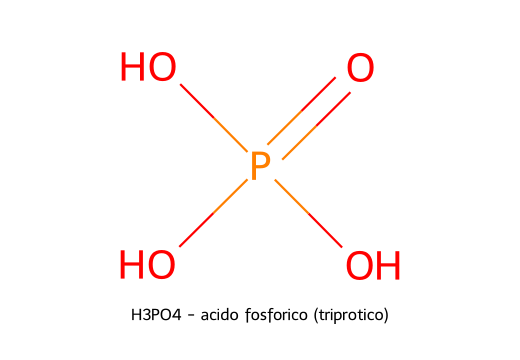

In [5]:
# @title Estrutura 2D com os risquinhos das ligações
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG

rdDepictor.SetPreferCoordGen(True)   # layout 2D no estilo de livro didático

def estrutura_2d(smiles, legenda="", largura=520, altura=360, mostrar_h=False):
    """SMILES -> SVG. Um traço = simples, dois = dupla, três = tripla.

    A legenda fica em ASCII porque o desenho do RDKit corrompe acento e
    subscrito (para título bonito, use matplotlib).
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    if mostrar_h:
        mol = Chem.AddHs(mol)
    rdDepictor.Compute2DCoords(mol)

    desenho = rdMolDraw2D.MolDraw2DSVG(largura, altura)
    desenho.drawOptions().bondLineWidth = 2.2
    desenho.drawOptions().padding = 0.10
    desenho.DrawMolecule(mol, legend=legenda)
    desenho.FinishDrawing()
    return SVG(desenho.GetDrawingText())

estrutura_2d("OS(=O)(=O)O", legenda="H2SO4 - acido sulfurico (diprotico)")
estrutura_2d("OP(=O)(O)O", legenda="H3PO4 - acido fosforico (triprotico)")

### 4.4 Galeria: os oxiácidos do cloro

Aqui a diferença entre eles é só o número de oxigênios — exatamente o que a regra de Pauling conta.

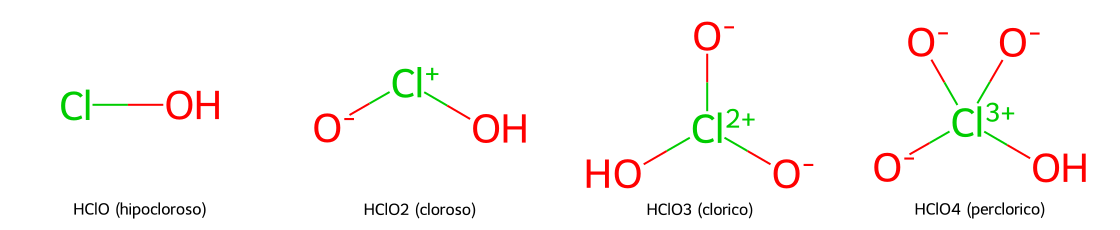

In [6]:
# @title Oxoácidos do cloro
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import SVG

oxoacidos = [("HClO (hipocloroso)", "ClO"),
             ("HClO2 (cloroso)", "O=ClO"),
             ("HClO3 (clorico)", "O=Cl(=O)O"),
             ("HClO4 (perclorico)", "O=Cl(=O)(=O)O")]
imagem = Draw.MolsToGridImage([Chem.MolFromSmiles(s) for _, s in oxoacidos],
                              molsPerRow=4, subImgSize=(280, 230),
                              legends=[nome for nome, _ in oxoacidos], useSVG=True)
imagem if hasattr(imagem, "data") else SVG(imagem)

### 4.5 p$K_a$ previsto × real

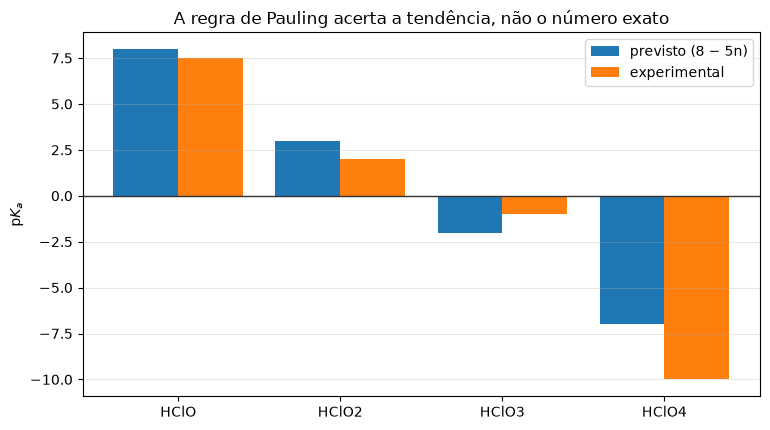

In [7]:
# @title Pauling x valores experimentais
import matplotlib.pyplot as plt

rotulos = [formula for formula, *_ in oxiacidos]
previstos = [pka_pauling(n) for _, _, n, _ in oxiacidos]
reais = [real for _, _, _, real in oxiacidos]
posicoes = range(len(rotulos))

plt.figure(figsize=(7.8, 4.4))
plt.bar([p - 0.2 for p in posicoes], previstos, width=0.4, label="previsto (8 − 5n)")
plt.bar([p + 0.2 for p in posicoes], reais, width=0.4, label="experimental")
plt.xticks(list(posicoes), rotulos)
plt.axhline(0, color="#333", linewidth=1)
plt.ylabel("p$K_a$")
plt.title("A regra de Pauling acerta a tendência, não o número exato")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 4.6 A mesma lógica nos halogênios

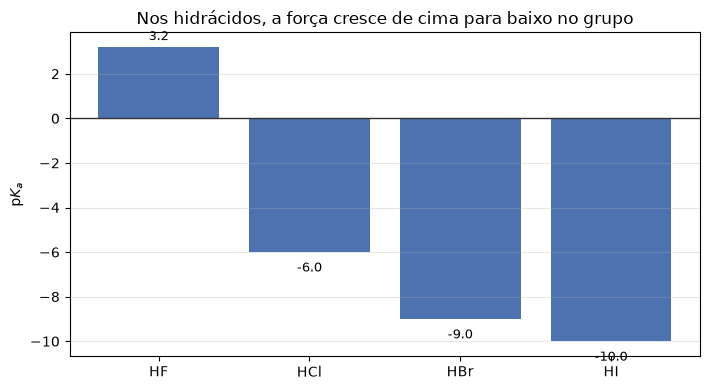

In [8]:
# @title Força dos hidrácidos
hidracidos = ["HF", "HCl", "HBr", "HI"]
pka_hidracidos = [3.2, -6.0, -9.0, -10.0]

plt.figure(figsize=(7.2, 4.0))
plt.bar(hidracidos, pka_hidracidos, color="#4c72b0")
for i, valor in enumerate(pka_hidracidos):
    plt.annotate(f"{valor:.1f}", (i, valor), xytext=(0, 5 if valor > 0 else -14),
                 textcoords="offset points", ha="center", fontsize=9)
plt.axhline(0, color="#333", linewidth=1)
plt.ylabel("p$K_a$")
plt.title("Nos hidrácidos, a força cresce de cima para baixo no grupo")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Como interpretar o resultado

- A terminação está sempre amarrada ao ânion: quem sabe nomear o ânion, sabe nomear o ácido.
- A regra de Pauling dá a **ordem** correta, mas erra o valor absoluto (prevê $-7$ para o perclórico, mede-se $-10$). Use como tendência, não como dado.
- Meia-vida de memorização: "um oxigênio a mais → $10^5$ vezes mais forte" é o que cai em prova.
- Nos hidrácidos a ordem se inverte em relação à eletronegatividade: o HF é o **mais fraco** do grupo, porque a ligação H–F é muito curta e forte.

## 6. Exercício de fixação

O ânion clorato é $\mathrm{ClO_3^-}$. Escreva a fórmula e o nome do ácido correspondente, estime o $\mathrm{p}K_a$ pela regra de Pauling e diga se ele é mais forte ou mais fraco que o ácido cloroso ($\mathrm{HClO_2}$).

In [9]:
# @title Exercício
# ânion "ato" -> ácido "ico": ClO3- -> HClO3 (ácido clórico)
n_ex = 2          # O totais (3) menos O do OH (1)
print("ácido: HClO3 — acido clorico")
print(f"n (O terminais) = {n_ex}")
print(f"pKa previsto = {pka_pauling(n_ex):.0f}")
print(f"o cloroso (HClO2, n = 1) tem pKa previsto {pka_pauling(1):.0f}")
print("logo, o clórico é MUITO mais forte: 5 unidades de pKa = 10^5 vezes")

ácido: HClO3 — acido clorico
n (O terminais) = 2
pKa previsto = -2
o cloroso (HClO2, n = 1) tem pKa previsto 3
logo, o clórico é MUITO mais forte: 5 unidades de pKa = 10^5 vezes


## 7. Resumo

- Sufixos: ânion *eto* → ácido *ídrico*; *ito* → *oso*; *ato* → *ico*.
- Oxiácido ganha força com mais oxigênios terminais: $\mathrm{p}K_a \approx 8 - 5n$.
- A ressonância estabiliza o ânion e é a razão física da regra de Pauling.
- Hidrácidos: força cresce com o tamanho do halogênio (HF é o mais fraco).
- Prefixos *hipo-* (menos O) e *per-* (mais O) completam a família.

## Referências

- IUPAC. *Nomenclature of Inorganic Chemistry* (Red Book).
- ATKINS, P.; JONES, L. *Princípios de Química*. Bookman.
- PAULING, L. *The Nature of the Chemical Bond*. Cornell.